# Encoding Geographical Risk from a Global Sanction Datasets

## A Structured Open Source Intelligence Tool to support Regulatory and AML/CFT Compliance
---

**Author**: Francesco Silvano, MEng in Engineering Management  

**Instructors**: Prof. Marco Maggini, Prof. Federico Becattini

**Course**: Business Intelligence, University of Siena 

**Publication Date**: June 2026

---

## Introduction & Context

Business analysts require powerful tools to handle complex data collection and analysis. Cross-referencing datasets is still a time-consuming and costly process. Open-source solutions tend to be inferior in terms of data quality, retrieval speed and user-friendliness, particularly when it comes to high-stakes sanctions compliance involving intricate data. 

Businesses engage with dozens of counterparties (such as suppliers, clients, intermediaries and investors) every day, and face structural information asymmetry with measurable consequences for risk. This project therefore proposes a sanctions intelligence system that uses open-source datasets to map entity relationships, detect evasion patterns and provide actionable insights via an interactive dashboard. 

It identifies potential patterns and factors influencing sanctions risks, thereby informing better compliance practices and policy decisions within the industry. The dataset comprises a comprehensive collection of sanctions-related entities and connections. The analysis focuses on identifying evasion patterns and risk propagation.

---

### Methodology

The datasets employed in this analysis are publicly sourced from [OpenSanctions](https://opensanctions.org), a public repository of global sanction data. The datasets include information on sanctioned entities - people, organizations and vessels - as well as complementary data on politically exposed persons (PEPs) and financial securities. 

The built pipeline ingests and combines multiple datasets, clean data ensuring that datasets are in a usable format and that any inconsistencies or missing values are addressed; an enrichment layer includes sanctioned maritime vessels and financial securities through complementary data joins - providing an holistic view of the activities carried out by sanctioned entities.

In Part I a thorough exploration of the datasets is perfomed to understand the distribution and quality of data across different types of entities and countries; in Part II we build the analytical layers: the data mining layer attempts to identify frequent patterns and associations in the data using an A-Priori algorithm for frequent itemsets and Jaccard Similarity for entity deduplication and collaborative filtering, while a recommendation system based on UV-decomposition via Stochastic Gradient Descent (SGD) suggests potential connections between entities based on their attributes and relationships; In Part III, a simple machine learning model is proposed to predict risk levels based on geographical and entity-specific features, providing a probabilistic assessment of potential sanctions evasion. 

#### A few assumptions to be aware of

The analysis is based on the assumption that the datasets used are comprehensive and accurate representations of the entities and relationships involved in sanctions. While OpenSanctions is an authorative source, and their updates are frequent, the available data may not capture all information in real time, and there may be gaps or inaccuracies.

Moreover, OpenSactions distributes data in the _FollowTheMoney (FTM)_ format, which is a specific structure for representing entities and their relationships. This format is in JSON, which requires significant preprocessing to be transformed into a structured format suitable for analysis. For the purpose of this analysis, a simpler version of the data in CSV format is used, which may not capture all the nuances and details present in the original JSON data.

The cut-off date for the data is set to 10/06/2026, and any events or changes that occurred after this date are not included in the analysis. This means that the findings may not reflect the most current state of sanctions and related activities.

### Technology Dependencies

```
0 Setup
└── 1 Ingest
    └── 2 Features
        ├── 3 Jaccard Dedup  ──────────────────────────────┐
        │   └── [deduped]                                  │
        │       ├── 4 Frequent Itemsets                    │
        │       │   └── [rules, fi_flags]                  │
        │       ├── 5 Network                              │
        │       │   └── [G, centrality, communities]       │
        │       │       ├── 6 Recommendation System        │
        │       │       │   └── [risk_score via UV]        │
        │       │       └── 7 ML Classifier ───────────────┘
        │       │           └── [risk_score]
        │       └── 8 Evasion Detection
        │           └── [evasion_score, evasion_flag]
        └── 9 Quarto Dashboard for Visualization
```

### Possible applications
---

| # | Application | Description | Example |
| --- | --- | --- | --- |
| 1 | Policy Evaluation and Public Accountability | Lorem Ipsum | Lorem Ipsum |
| 3 | Risk Management | Lorem Ipsum | Lorem Ipsum |
| 4 | Resource Allocation and Prioritisation | Lorem Ipsum | Lorem Ipsum |
| 5 | Decision Support Systems | Creating decision support tools for KYC/KYB functions in corporations and policymakers that leverage data insights to optimise project planning, execution, and monitoring processes. | Lorem Ipsum |

---

### Libraries and Imports

In [21]:
# Data
import pandas as pd
import numpy as np
from scipy import stats

# Other tools
import json, re, hashlib, itertools, collections, math, warnings
from pathlib import Path

# Similarity
from datasketch import MinHash, MinHashLSH        # MinHash-based Jaccard LSH

# A-Priori Algorithm
from mlxtend.frequent_patterns import apriori, association_rules 
from mlxtend.preprocessing import TransactionEncoder

# LDA, QDA use module: scikit learn
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.inspection import DecisionBoundaryDisplay

# Vizualization
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

# Machine Learning
# from sklearn.linear_model import SGDClassifier
# from sklearn.preprocessing import StandardScaler
# from sklearn.pipeline import Pipeline
# from sklearn.metrics import (classification_report, roc_auc_score,
#                              average_precision_score)
# from sklearn.model_selection import StratifiedKFold
# from scipy.sparse import lil_matrix, csr_matrix

DATA_PATH = "data/input"

### Collection and Update Process

The dataset _coverage_ [^1] - so when it was started and how frequently it is updated - is "on the hour", every 6 hours, and reflect the latest submissions and updates from the original sources. The dataset is updated automatically, however for the purpose of this project, a static snapshot of the data was taken on 10/06/2026 - the date on which a final analysis has been run - to ensure consistency across the analysis and avoid potential issues with data changes during the project timeline. 

[^1]: We use the term coverage inside dataset metadata to describe when a dataset is added to the database (dataset.coverage.start), and how often it is updated. While most data sources are updated automatically in specific intervals (the update frequency, dataset.coverage.frequency), this there are some exceptions. This includes datasets where the original publisher has stopped releasing updates of the data, and datasets where we cannot fully automate the retrieval process (e.g. because of a firewall preventing automated access, or because the data is released in an unstructured form that requires manual cleaning). Some datasets are simply static documents: lists mandated by a law, or reports that are only published once.

### Data Quality

The data in this collection originates from a variety of sources and therefore varies in terms of detail and precision (e.g., many listings of political office holders do not include their exact birth dates or full given names).

This represents a significant challenge for data quality, as it can lead to difficulties in entity resolution and risk assessment. For instance, the lack of precise identifiers may result in false positives or negatives when screening for sanctioned entities, which can have serious implications for compliance efforts. 

In general, to mitigate these issues, the dataset includes metadata on the source and confidence level of each entry, allowing users to assess the reliability of the information and make informed decisions based on the available data. However these information are only available in the JSON file. For the purpose of this analysis a simpler CSV that lacks all the detailed information of the JSON. 

### Limitations

| Limitation Type | Description | Dataset | 
| --- | --- | --- |
| Data Completeness | Sanctions Sanctions designation wouldn’t be in the PEPs collection because those sources don’t contain the designations texts. The correct thing to do would be to filter the default dataset for entities with both the topics “sanction” and “role.pep”. This would be a more accurate way to identify PEPs that are also sanctioned, but it would also significantly reduce the number of entities in the dataset, which may limit the analysis. However, the topics are not included in the targets.simple.csv, they are only in the JSON. | Consolidated Sanctions, PEPs |

---

## Part I: Data Exploration and Preprocessing
---

### Describing the main datasets

#### DS1 Consolidated Sanctions

The _"Consolidated Sanctions"_ dataset is a distribution listing all the sanctioned entities designated by different countries and  international organisations. This can include military, trade and travel restrictions.

This collection combines all designated entities from the various sanctions lists included in OpenSanctions. It represents the broadest set of sanctioned people, companies and other assets that is designated globally.

In [34]:
# Load the data for Consolidated Sanctions dataset
df_consolidated = pd.read_csv(f"{DATA_PATH}/consolidatedsanctions/targets.simple-1.csv", low_memory=False).drop(columns=['phones','emails']) # phones and emails are dropped for simplicity
df_consolidated['countries'] = df_consolidated['countries'].str.upper()

#### DS2 Politically Exposed Persons (PEPs) dataset

The _"Politically Exposed Persons (PEPs)"_ dataset is a collection of individuals who are or have been entrusted with prominent public roles.

This dataset is important for financial institutions and other entities that are required to conduct enhanced due diligence on PEPs to mitigate risks of corruption and money laundering. It includes information on the individual's name, position, country of origin, and any associated risks.

In [36]:
# Load the data for the PEPs dataset
df_peps = pd.read_csv(f'{DATA_PATH}/peps/targets.simple-1.csv', low_memory=False) # low_memory=False to avoid dtype warnings
df_peps['countries'] = df_peps['countries'].str.upper()
df_peps

,id,schema,name,aliases,birth_date,countries,addresses,identifiers,sanctions,phones,emails,program_ids,dataset,first_seen,last_seen,last_change
0,NK-24KdLmG7SRFdS5GgJbgLSs,Person,"AW Kim Geok, PBS, PPA(P)",NaN,NaN,SG,NaN,NaN,NaN,NaN,aw_kim_geok@ite.edu.sg,NaN,Singapore Government Directory,2025-02-14T11:49:46,2026-05-06T00:07:19,2025-02-14T11:49:46
1,NK-24W9aosPLEsueQ5grGVNiK,Person,Christophane FOO,NaN,NaN,SG,NaN,NaN,NaN,NaN,Christophane_FOO@enterprisesg.gov.sg,NaN,Singapore Government Directory,2025-02-14T11:49:46,2026-05-06T00:07:19,2025-02-14T11:49:46
2,NK-24umfCYjCezXnS2gcCfT8F,Person,Andreas Norvik,NaN,1969-09-26,NO,NaN,NaN,NaN,NaN,NaN,NaN,Norway State-Owned Enterprises Leadership,2026-02-23T22:56:15,2026-04-22T14:39:39,2026-02-23T22:56:15
3,NK-25bxtBgjBTs6asnevNVgsE,Person,Sambhaji Rao Shinde,Shri Sambhaji Rao Shinde,NaN,IN,NaN,NaN,NaN,NaN,NaN,NaN,India Lok and Rajya Sabha Members,2025-10-13T12:10:55,2026-05-05T16:16:02,2025-10-13T12:10:55
4,NK-29DHCApxL2XswzxpKc6wva,Person,Rolf Skatteboe,NaN,1960-06-11,NO,NaN,NaN,NaN,NaN,NaN,NaN,Norway State-Owned Enterprises Leadership,2026-02-23T22:56:15,2026-04-22T14:39:39,2026-02-23T22:56:15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
741919,za-pmg-fc07125b875c410b7b81c9be51aa86b50a71e2c4,Person,Linda Xolelwa Hlobisile Hlongwa-Madlala,NaN,NaN,ZA,"Office 10, Dr Murugan Building, 5 Main Street ...",NaN,NaN,NaN,hlongwal@kznleg.gov.za,NaN,PEP position annotations by OpenSanctions;Sout...,2024-09-05T16:32:57,2026-05-07T13:37:03,2026-02-05T20:31:23
741920,za-pmg-fc1a0358099a1f66a7abac48528a39ca0416968a,Person,Fulufhelo Florence Radzilani,NaN,1970-09-14,ZA,Department of Health and Social Development Bu...,NaN,NaN,NaN,FrancisS@dsd.limpopo.gov.za;shivanifrancis26@g...,NaN,PEP position annotations by OpenSanctions;Sout...,2024-09-05T16:32:57,2026-05-07T13:37:03,2026-02-05T20:31:23
741921,za-pmg-fdd48f3a188d84f89e0074716820da3dafc87af1,Person,Anele Ernest Lizo,NaN,1983-12-17,ZA,NaN,NaN,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Sout...,2024-09-05T16:32:57,2026-05-07T13:37:03,2026-02-05T20:31:23
741922,za-pmg-ff8ca6eb6f9638b63d158c5fa822ff092a406e7f,Person,Khethiwe Mildred Muthwa,NaN,NaN,ZA,NaN,NaN,NaN,NaN,NaN,NaN,South Africa National and Provincial Legislators,2024-09-05T16:32:57,2026-05-06T20:44:02,2026-02-05T20:31:23


In [9]:
df_peps.head()
n_peps = df_peps['id'].nunique() # check number of unique entities in PEPs dataset
n_duplicates = df_peps['name'].duplicated().sum() # check for duplicates in PEPs dataset

print(f"Number of unique entities in PEPs dataset: {n_peps}")
print(f"Number of duplicates in PEPs dataset: {n_duplicates}")

# create a new dataframe with n_duplicates
# df_duplicates = df_peps[df_peps['name'].duplicated(keep=False)].sort_values('name')

df_duplicates = df_peps[df_peps['name'].duplicated(keep=False)].sort_values('name')
df_duplicates

Number of unique entities in PEPs dataset: 741924
Number of duplicates in PEPs dataset: 29095


,id,schema,name,aliases,birth_date,countries,addresses,identifiers,sanctions,phones,emails,program_ids,dataset,first_seen,last_seen,last_change
717606,sg-gov-a7992d9cdc07e49350b0880ad949143ec05da841,Person,A SELVERAJAH,NaN,NaN,SG,NaN,NaN,NaN,NaN,A_SELVERAJAH@mfa.gov.sg,NaN,Singapore Government Directory,2025-02-14T11:49:46,2026-05-06T00:07:19,2025-02-14T11:49:46
720098,sg-gov-c7f1e742c4a9b6f9a68d52835dbb52e465bf6614,Person,A SELVERAJAH,NaN,NaN,SG,NaN,NaN,NaN,NaN,A_SELVERAJAH@mfa.gov.sg,NaN,Singapore Government Directory,2025-02-14T11:49:46,2026-05-06T00:07:19,2025-02-14T11:49:46
161257,Q30524075,Person,A. Mani,NaN,NaN,IN,NaN,Q30524075,NaN,NaN,NaN,NaN,Wikidata Persons in Relevant Categories,2024-09-04T09:26:39,2026-05-06T03:53:24,2026-01-07T00:12:12
80738,Q133865340,Person,A. Mani,Mani A,1968-08-31,IN,"2/255A, Koodakaran Kottai Village A. Sappanipa...",Q133865340,NaN,NaN,NaN,NaN,India Lok and Rajya Sabha Members;PEP position...,2025-04-15T04:18:56,2026-05-07T13:37:03,2026-01-21T13:37:01
179699,Q4648173,Person,A. Marimuthu,NaN,NaN,IN,NaN,Q4648173,NaN,NaN,NaN,NaN,Wikidata Persons in Relevant Categories,2024-09-04T09:26:39,2026-05-06T03:53:24,2026-01-16T00:12:01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66092,Q130539861,Person,신동준,NaN,1932-12-10,KR,NaN,Q130539861,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Wiki...,2025-05-05T12:48:14,2026-05-07T13:37:03,2026-01-15T03:48:43
66082,Q130539617,Person,이영애,NaN,1951-09-23,KR,NaN,Q130539617,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Wiki...,2025-05-05T12:48:14,2026-05-07T13:37:03,2026-01-15T03:48:43
199403,Q55733317,Person,이영애,NaN,1948-09-21,KR,NaN,Q55733317,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Wiki...,2025-03-31T13:59:24,2026-05-07T13:37:03,2026-01-16T00:12:01
59541,Q12619700,Person,최영희,NaN,1950-07-20,KR,NaN,Q12619700,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Wiki...,2025-03-31T13:59:24,2026-05-07T13:37:03,2026-01-15T03:48:43


### Cleaning the main datasets

Although no extensive cleaning process was required for the datasets, as they were already in a structured format and did not contain significant missing values or inconsistencies, some preprocessing steps were necessary to ensure the data was in a usable format for analysis.

The PEPs dataset, in particular, required a deduplication process due to the presence of duplicates across different sources.

The deduplication process was implemented by simply keeping the occurrence with the most complete information, i.e. the row with the least number of missing values across all columns. This approach ensured that we retained the most informative record for each unique entity while eliminating redundant entries that could jeopardize the accuracy of our analysis. 

In [43]:
df_peps_work = df_peps.copy()
df_peps_work['non_null_count'] = df_peps_work.count(axis=1)

df_peps_work = df_peps_work.sort_values('non_null_count', ascending=False).drop_duplicates(subset='name', keep='first')

print(f"Number of unique entities: {df_peps_work['name'].nunique()}")
print(f"Number of duplicates removed: {df_peps.shape[0] - df_peps_work.shape[0]}")

Number of unique entities: 712829
Number of duplicates removed: 29095


In [40]:
df_peps_work

,id,schema,name,aliases,birth_date,countries,addresses,identifiers,sanctions,phones,emails,program_ids,dataset,first_seen,last_seen,last_change,non_null_count
196776,Q54861079,Person,Mohamed-Iqbal Ravalia,"Ravalia, Mohamed-Iqbal",1957-08-15,CA;FR,Newfoundland and Labrador,Q54861079,NaN,+16139433676,Mohamed-iqbal.ravalia@sen.parl.gc.ca,NaN,Canada Members of the Senate;MySociety's Every...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T09:37:31,14
49049,Q121862,Person,Erich Hess,"Hess, Erich;Эрих Гесс;إريك هس",1981-03-25,CH,Berne;Dürrenroth,Q121862,NaN,+41313984200,erich.hess@parl.ch,NaN,MySociety's EveryPolitician Legislators;PEP po...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T10:26:30,14
131745,Q19853823,Person,Peter Shiu,SHIU Ka-fai;邵家輝;邵家辉,1970-04-22,CN;HK,"Room 1112, Legislative Council Complex, 1 Legi...",Q19853823,NaN,+85225373627;2537 3627,info@shiukafai.hk;kfshiu003@yahoo.com.hk,NaN,Hong Kong Legislative Council Members;MySociet...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T09:37:31,14
44908,Q11887897,Person,Pia Kauma,Kauma Pia;Pia Liisa Kauma,1966-10-20,FI,Espoo,Q11887897,NaN,+35894323069,pia.kauma@eduskunta.fi,NaN,Finland Members of Parliament;MySociety's Ever...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T09:37:31,14
44909,Q11887901,Person,Pia Viitanen,"Pia-Liisa Viitanen;Viitanen Pia;Вийтанен, Пиа",1967-04-07,FI,Tampere,Q11887901,NaN,+35894323039,pia.viitanen@eduskunta.fi,NaN,Finland Members of Parliament;MySociety's Ever...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T09:37:31,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
701575,ng-dots-precious-chikwendu-of-ng-dots-femi-fan...,Person,Precious Chikwendu,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Nigeria Joining the Dots PEPs and PEP Relatives,2023-10-23T10:04:48,2026-05-07T05:29:01,2023-10-23T10:04:48,7
701641,ng-dots-sa-ad-usman-of-ng-dots-nenadi-esther-u...,Person,Sa’Ad Usman,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Nigeria Joining the Dots PEPs and PEP Relatives,2023-10-23T10:04:48,2026-05-07T05:29:01,2023-10-23T10:04:48,7
702026,ng-dots-uzodinma-iweala-of-ng-dots-ngozi-okonj...,Person,Uzodinma Iweala,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Nigeria Joining the Dots PEPs and PEP Relatives,2023-10-23T10:04:48,2026-05-07T05:29:01,2023-10-23T10:04:48,7
702091,ng-dots-yuki-omenai-of-ng-dots-daisy-danjuma-1...,Person,Yuki Omenai,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Nigeria Joining the Dots PEPs and PEP Relatives,2023-10-23T10:04:48,2026-05-07T05:29:01,2023-10-23T10:04:48,7


In [12]:
df_sanctioned_people = df_consolidated[df_consolidated['schema'] == 'Person']
df_sanctioned_people

,id,schema,name,aliases,birth_date,countries,addresses,identifiers,sanctions,program_ids,dataset,first_seen,last_seen,last_change
6,NK-22HtK7WrxZ2sU3rmhz6PuZ,Person,Michael Kuajien,"KUAJIEN, Michael;Michael Kuajian;Michael Kuaji...",1979-01-01,KE;SS,Nairobi,NaN,GLOMAG - Executive Order 13818 (Global Magnitsky),US-GLOMAG,US OFAC Specially Designated Nationals (SDN) L...,2023-04-20T10:27:20,2026-05-08T06:54:29,2026-01-26T16:10:01
7,NK-22KNpaKJL84d8wpFudvLjN,Person,Чантурія Іраклі,CHANTURIA IRAKLI;CHANTURIA IRAKLII;Chanturiia ...,1983-05-29,GE;UA,NaN,NaN,203/2021 - updated - 2021-05-21;497/2021 - act...,UA-SA1644,Ukraine NSDC State Register of Sanctions,2023-04-20T10:50:14,2026-05-08T00:22:02,2026-01-06T08:22:01
11,NK-22c6upVtxbVMhbZb3Z6dn6,Person,Старовойтов Станіслав Юрійович,Starovoitov Stanislav;Starovoitov Stanislav Yu...,1982-10-11,RU,"Російська Федерація, Томська область, с. Бакчар",701722661674,726/2022 - active - 2022-10-19 - 2027-10-19,UA-SA1644,Ukraine NSDC State Register of Sanctions,2023-04-20T10:50:14,2026-05-08T00:22:02,2026-01-06T08:22:01
13,NK-22pPzcnpXeHiUgdXU3RcT8,Person,Дедюхін Олег Васильович,Dediukhin Oleg;Dediukhin Oleh Vasylovych;Дедюх...,1954-10-12,RU,NaN,165904188211,"295/2026 - дії іноземної держави, іноземної юр...",UA-SA1644,Ukraine NSDC State Register of Sanctions,2026-04-04T08:22:01,2026-05-08T00:22:02,2026-04-04T08:22:01
14,NK-22tXKtJr4xMCbfKZr5RzEz,Person,Khalid SBAA,NaN,1989-01-23,NaN,NaN,NRN 89.01.23-529.75,"""""",NaN,Belgian Financial Sanctions,2025-12-01T20:51:03,2026-05-08T06:17:09,2025-12-01T20:51:03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69610,us-klepto-hr-visa-venezuela-victor-jesus-lugo-...,Person,Victor Jesus Lugo Lugo,NaN,NaN,VE,NaN,NaN,Actions Taken Pursuant to Section 7031(c) for ...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26
69611,us-klepto-hr-visa-venezuela-virginia-del-valle...,Person,Virginia Del Valle Lugo Lugo,NaN,NaN,VE,NaN,NaN,Actions Taken Pursuant to Section 7031(c) for ...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26
69612,us-klepto-hr-visa-venezuela-yomaira-isabela-lu...,Person,Yomaira Isabela Lugo de Lugo,NaN,NaN,VE,NaN,NaN,Actions Taken Pursuant to Section 7031(c) for ...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26
69613,us-klepto-hr-visa-vietnam-vo-thanh-dung,Person,Vo Thanh Dung,NaN,NaN,VN,NaN,NaN,Actions Taken Pursuant to Section 7031(c)(1) f...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26


The `df_sanctioned_people` dataframe contains only the entities from the Consolidated Sanctions dataset that are classified as 'Person' under the 'schema' column. These are all the individuals that have been designated as sanctioned entities by different countries and international organisations.

#### Distribution of sanctioned individuals by country

##### Sanctioned individuals that are not PEPs

In [13]:
df_sanctioned_people_nopeps = df_sanctioned_people[~df_sanctioned_people['id'].isin(df_peps_def['id'])]
df_sanctioned_people_nopeps

,id,schema,name,aliases,birth_date,countries,addresses,identifiers,sanctions,program_ids,dataset,first_seen,last_seen,last_change
6,NK-22HtK7WrxZ2sU3rmhz6PuZ,Person,Michael Kuajien,"KUAJIEN, Michael;Michael Kuajian;Michael Kuaji...",1979-01-01,KE;SS,Nairobi,NaN,GLOMAG - Executive Order 13818 (Global Magnitsky),US-GLOMAG,US OFAC Specially Designated Nationals (SDN) L...,2023-04-20T10:27:20,2026-05-08T06:54:29,2026-01-26T16:10:01
7,NK-22KNpaKJL84d8wpFudvLjN,Person,Чантурія Іраклі,CHANTURIA IRAKLI;CHANTURIA IRAKLII;Chanturiia ...,1983-05-29,GE;UA,NaN,NaN,203/2021 - updated - 2021-05-21;497/2021 - act...,UA-SA1644,Ukraine NSDC State Register of Sanctions,2023-04-20T10:50:14,2026-05-08T00:22:02,2026-01-06T08:22:01
11,NK-22c6upVtxbVMhbZb3Z6dn6,Person,Старовойтов Станіслав Юрійович,Starovoitov Stanislav;Starovoitov Stanislav Yu...,1982-10-11,RU,"Російська Федерація, Томська область, с. Бакчар",701722661674,726/2022 - active - 2022-10-19 - 2027-10-19,UA-SA1644,Ukraine NSDC State Register of Sanctions,2023-04-20T10:50:14,2026-05-08T00:22:02,2026-01-06T08:22:01
13,NK-22pPzcnpXeHiUgdXU3RcT8,Person,Дедюхін Олег Васильович,Dediukhin Oleg;Dediukhin Oleh Vasylovych;Дедюх...,1954-10-12,RU,NaN,165904188211,"295/2026 - дії іноземної держави, іноземної юр...",UA-SA1644,Ukraine NSDC State Register of Sanctions,2026-04-04T08:22:01,2026-05-08T00:22:02,2026-04-04T08:22:01
14,NK-22tXKtJr4xMCbfKZr5RzEz,Person,Khalid SBAA,NaN,1989-01-23,NaN,NaN,NRN 89.01.23-529.75,"""""",NaN,Belgian Financial Sanctions,2025-12-01T20:51:03,2026-05-08T06:17:09,2025-12-01T20:51:03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69610,us-klepto-hr-visa-venezuela-victor-jesus-lugo-...,Person,Victor Jesus Lugo Lugo,NaN,NaN,VE,NaN,NaN,Actions Taken Pursuant to Section 7031(c) for ...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26
69611,us-klepto-hr-visa-venezuela-virginia-del-valle...,Person,Virginia Del Valle Lugo Lugo,NaN,NaN,VE,NaN,NaN,Actions Taken Pursuant to Section 7031(c) for ...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26
69612,us-klepto-hr-visa-venezuela-yomaira-isabela-lu...,Person,Yomaira Isabela Lugo de Lugo,NaN,NaN,VE,NaN,NaN,Actions Taken Pursuant to Section 7031(c) for ...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26
69613,us-klepto-hr-visa-vietnam-vo-thanh-dung,Person,Vo Thanh Dung,NaN,NaN,VN,NaN,NaN,Actions Taken Pursuant to Section 7031(c)(1) f...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26


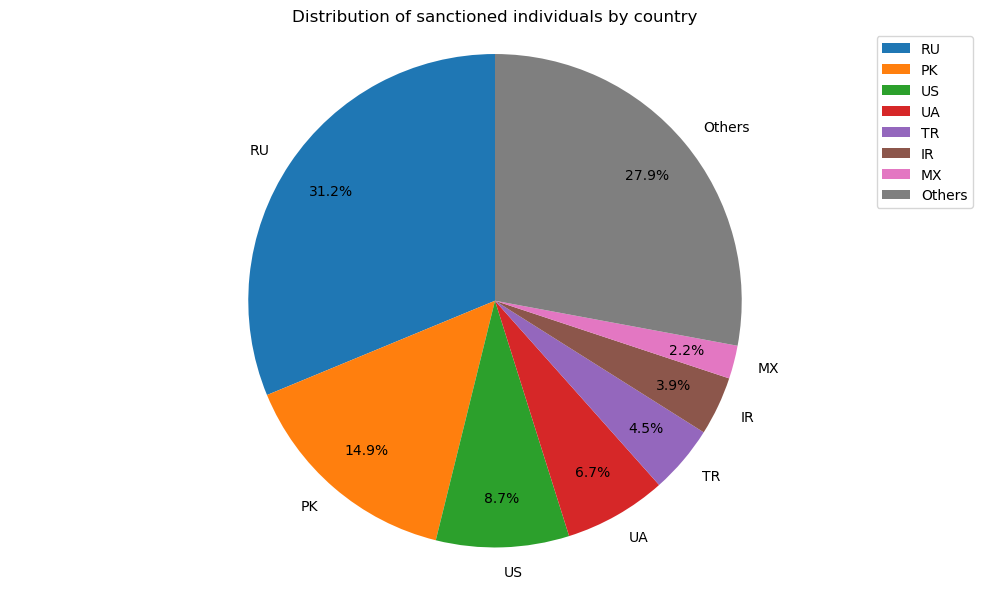

In [50]:
country_counts_nopeps = df_sanctioned_people_nopeps['countries'].str.split(';').explode().str.strip().value_counts()

country_percentage_nopeps = country_counts_nopeps / country_counts_nopeps.sum()

main_countries_nopeps = country_counts_nopeps[country_percentage_nopeps >= 0.02]
other_countries_nopeps = country_counts_nopeps[country_percentage_nopeps < 0.02].sum()

plot_data = main_countries_nopeps.copy()
if other_countries_nopeps > 0:
    plot_data['Others'] = other_countries_nopeps

fig = plt.figure(figsize=(10, 6))
plot_data.plot(
    kind='pie',
    autopct='%1.1f%%', # autopct to show percentage on the pie chart
    startangle=90,
    pctdistance=0.8
)

plt.title('Distribution of sanctioned individuals by country')
plt.axis('equal')
plt.tight_layout()
plt.legend()
plt.show()

##### Sanctioned individuals that are also PEPs

Analyzing the distribution of the sanctioned PEPs by country allows us to understand how many politically exposed persons are sanctioned in each country, and to identify any patterns or trends in the distribution of sanctions across different countries. This can provide insights into the geopolitical and economic factors that may influence sanctions designation, and can inform risk assessment and compliance efforts for entities operating in those countries.

In [57]:
df_sanctioned_people_peps = pd.merge(df_sanctioned_people, df_peps_work, on='id', how='inner', suffixes=('_consolidated', '_peps'))
df_sanctioned_people_peps

,id,schema_consolidated,name_consolidated,aliases_consolidated,birth_date_consolidated,countries_consolidated,addresses_consolidated,identifiers_consolidated,sanctions_consolidated,program_ids_consolidated,...,identifiers_peps,sanctions_peps,phones,emails,program_ids_peps,dataset_peps,first_seen_peps,last_seen_peps,last_change_peps,non_null_count
0,NK-BSEuishRCnUhGGStYWEtGt,Person,Hermann Eduardo ESCARRA MALAVE,"ESCARRA MALAVE, Hermann Eduardo;Hermann Eduard...",1952-04-08,VE,"Miranda, Miranda",3820195,VENEZUELA - Executive Order 13692 (Venezuela);...,CA-SEMA;US-VEN,...,NaN,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Vene...,2024-01-30T20:02:45,2026-05-07T13:37:03,2026-04-15T21:33:50,8
1,NK-BcU6kPxJiL4AeJn6f4ujwS,Person,America Valentina Perez Davila,"PEREZ DAVILA, America Valentina",1993-11-27,VE,NaN,V20901866,VENEZUELA - Executive Order 13692 (Venezuela),US-VEN,...,NaN,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Vene...,2024-01-30T20:02:45,2026-05-07T13:37:03,2026-04-15T21:33:50,8
2,NK-QeQteG9tqe895L4aaBfT85,Person,Emrush XHEMAJLI,"XHEMAJLI, Emrush",1959-05-05,NaN,NaN,NaN,BALKANS - Unknown,US-BALKANS,...,NaN,NaN,NaN,NaN,NaN,MySociety's EveryPolitician Legislators;PEP po...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T09:37:31,10
3,NK-SifJyUiXJfmymXcP5F89M7,Person,Ramiz LLADROVICI,"LLADROVICI, Ramiz",1966-01-03,NaN,NaN,NaN,BALKANS - Unknown,US-BALKANS,...,NaN,NaN,NaN,NaN,NaN,MySociety's EveryPolitician Legislators;PEP po...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T09:37:31,10
4,NK-TAZ2PvEBNvLMqgCBsz9BTe,Person,Andres Laureano Gonzalez Brito,"Andrés Laureano González Brito;GONZALEZ BRITO,...",1954-07-04,CU,Havana,NaN,GLOMAG - Executive Order 13818 (Global Magnitsky),US-GLOMAG,...,NaN,NaN,NaN,NaN,NaN,Cuba Members of the Parliament;PEP position an...,2023-08-14T15:43:35,2026-05-07T13:37:03,2026-03-16T09:36:35,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3338,Q99767942,Person,Alena PANTSIUKHOVA,NaN,1972-12-20,NaN,NaN,NaN,2023-05-30,NaN,...,Q99767942,NaN,NaN,NaN,NaN,Wikidata Persons in Relevant Categories;Wikida...,2023-04-20T10:30:17,2026-05-06T03:53:24,2026-01-15T03:48:43,10
3339,Q99769144,Person,Aliaksandr LIAKHAU,NaN,1962-07-07,NaN,NaN,NaN,2023-05-31,NaN,...,Q99769144,NaN,NaN,NaN,NaN,Wikidata Persons in Relevant Categories;Wikida...,2023-04-20T10:30:17,2026-05-06T03:53:24,2026-01-15T03:48:43,10
3340,Q99837867,Person,Aliaksandr SHYSHKO,NaN,1959-09-24,NaN,NaN,NaN,2023-05-30,NaN,...,Q99837867,NaN,NaN,NaN,NaN,Wikidata Persons in Relevant Categories;Wikida...,2023-04-20T10:30:17,2026-05-06T03:53:24,2026-01-15T03:48:43,10
3341,Q99861219,Person,Ivan Ivanavich GALAVATYI,Galavatyi Ivan Ivanavich;Golovaty Ivan Ivanovi...,1976-06-15,BY,NaN,NaN,(UE) 2025/386 du 24/02/2025 (UE Biélorussie - ...,CA-SEMA;EU-BLR;SECO-BRUS,...,Q99861219,NaN,NaN,NaN,NaN,Wikidata Persons in Relevant Categories;Wikida...,2023-04-20T10:30:17,2026-05-06T03:53:24,2026-01-18T00:12:11,10


The resulting dataset is typically named "The Russian Government" by the analysts for the presence of many high-profile Russian politicians and oligarchs who are both sanctioned and politically exposed. This subset can be analyzed further to understand the overlap between the two datasets and to identify any unique characteristics of these entities.

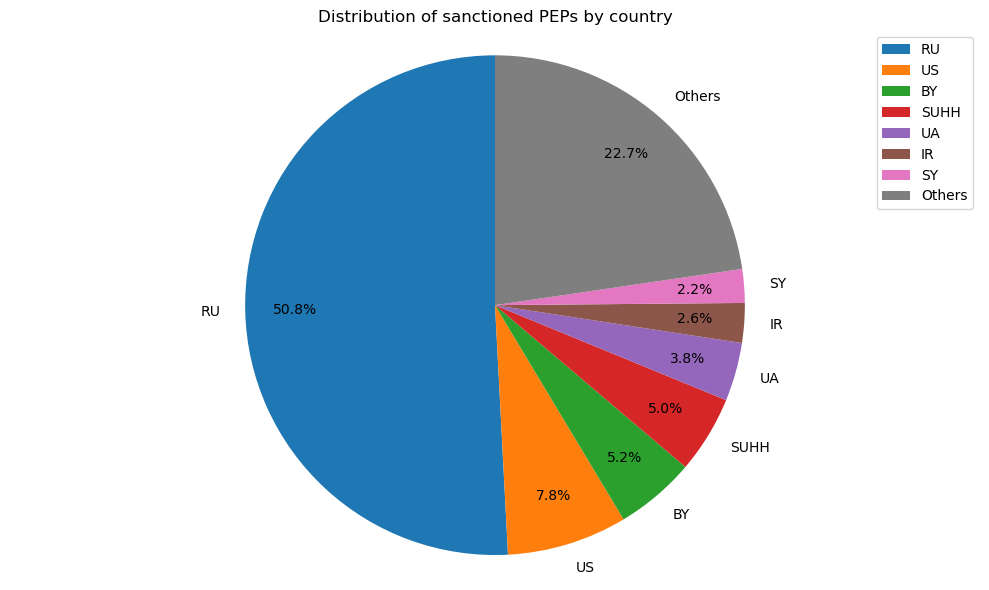

In [58]:
country_counts_peps = df_sanctioned_people_peps['countries_peps'].str.split(';').explode().str.strip().value_counts()

country_percentage_peps = country_counts_peps / country_counts_peps.sum()

main_countries_peps = country_counts_peps[country_percentage_peps >= 0.02]
other_countries_peps = country_counts_peps[country_percentage_peps < 0.02].sum()

plot_data = main_countries_peps.copy()
if other_countries_peps > 0:
    plot_data['Others'] = other_countries_peps

fig = plt.figure(figsize=(10, 6))
plot_data.plot(
    kind='pie',
    autopct='%1.1f%%', # autopct to show percentage on the pie chart
    startangle=90,
    pctdistance=0.8
)

plt.title('Distribution of sanctioned PEPs by country')
plt.axis('equal')
plt.tight_layout()
plt.legend()
plt.show()

### Describing the Enrichment Layers

#### Distribution of sanctioned non-individual entities by country

##### EL1 Sanctioned vessels

In [59]:
df_maritime = pd.read_csv(f'{DATA_PATH}/maritime/maritime.csv', low_memory=False) # low_memory=False to avoid dtype warnings
df_maritime['countries'] = df_maritime['countries'].str.upper()
df_maritime['flag'] = df_maritime['flag'].str.upper()

In [60]:
df_maritime

,type,caption,imo,risk,countries,flag,mmsi,id,url,datasets,aliases
0,VESSEL,BOUDREAUX TIDE,IMO9427366,mare.detained;reg.warn,VU,VU,NaN,abuja-mou-det-0059aae88f59011c58de8f5bc1d7d986...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
1,VESSEL,MT UNGIESHI,IMO9261841,mare.detained;reg.warn,PA,PA,NaN,abuja-mou-det-008a22106d7ad7f4d4e184b01bbd61f4...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
2,VESSEL,HACI SEMSETTIN DUNDAR,IMO9045699,mare.detained;reg.warn,PA,PA,NaN,abuja-mou-det-088511901b0456a70ec6288207972686...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
3,VESSEL,SIRAYA WISDOM,IMO9403841,mare.detained,PA,PA,NaN,abuja-mou-det-094320324411c3158780fc172d24b2cb...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
4,VESSEL,BBC OLYMPUS,IMO9508457,mare.detained,AG,AG,NaN,abuja-mou-det-0a5094c74d3f88de2254405dfe3d8aa1...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
...,...,...,...,...,...,...,...,...,...,...,...
17314,VESSEL,DONG FENG 6,IMO9008201,sanction,NaN,NaN,NaN,un-1718-f63806bb0ad4c75d3347907c5684a669fc4f636e,https://www.opensanctions.org/entities/un-1718...,un_1718_vessels,NaN
17315,VESSEL,Hangton No. 112,NaN,sanction,NaN,NaN,NaN,us-cbpfl-0b3f7392a785c689f86ea31cc4b21cef1eb2c00b,https://www.opensanctions.org/entities/us-cbpf...,us_cbp_forced_labor,NaN
17316,VESSEL,Lien Yi Hsing No. 12,NaN,sanction,NaN,NaN,NaN,us-cbpfl-6dd36877071adfe36f7652f93f5ba3bef70fa1ea,https://www.opensanctions.org/entities/us-cbpf...,us_cbp_forced_labor,NaN
17317,VESSEL,Zhen Fa 7,NaN,sanction,CN,NaN,NaN,us-cbpfl-b64c9884986c6a2bb6d5d1683e8700fd66645346,https://www.opensanctions.org/entities/us-cbpf...,us_cbp_forced_labor,NaN


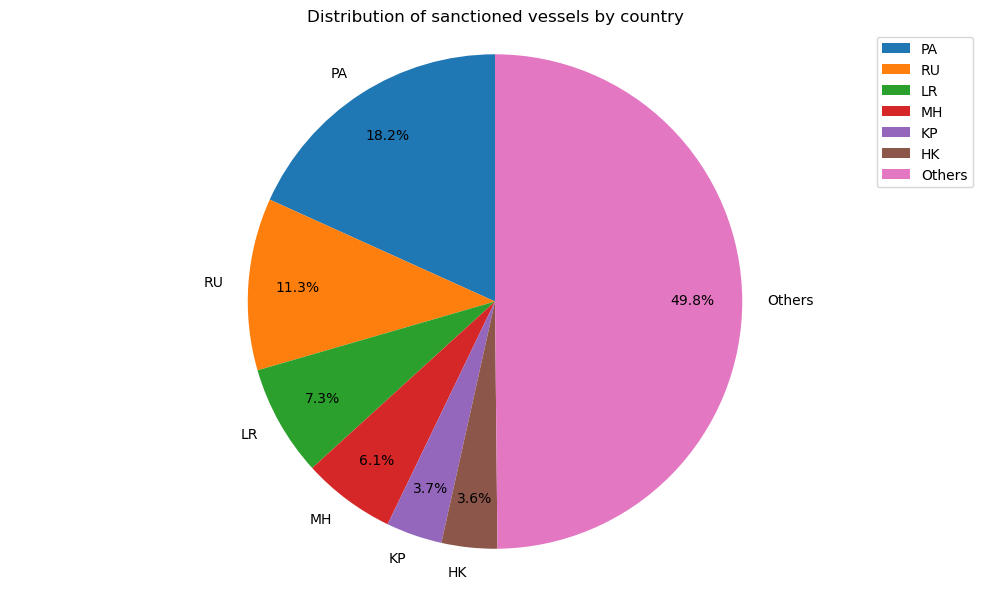

In [70]:
country_counts = df_maritime['countries'].value_counts()

country_percentage = country_counts / country_counts.sum()

main_countries = country_counts[country_percentage >= 0.02]
other_countries = country_counts[country_percentage < 0.02].sum()

plot_data = main_countries.copy()
if other_countries > 0:
    plot_data['Others'] = other_countries

fig = plt.figure(figsize=(10, 6))
plot_data.plot(
    kind='pie',
    autopct='%1.1f%%', # autopct to show percentage on the pie chart
    startangle=90,
    pctdistance=0.8
)

plt.title('Distribution of sanctioned vessels by country')
plt.axis('equal')
plt.tight_layout()
plt.legend()
plt.show()

##### EL2 Sanctioned securities

- By Sanctioned Securities we mean ...

In [38]:
df_securities = pd.read_csv(f'{DATA_PATH}/securities/securities.csv', low_memory=False)
df_securities['countries'] = df_securities['countries'].str.upper()

In [20]:
df_securities

,caption,lei,perm_id,isins,ric,countries,sanctioned,eo_14071,public,id,url,datasets,risk_datasets,aliases,referents
0,"Myanmar Yatai International Holding Group Co.,...",NaN,NaN,NaN,NaN,MM,t,f,f,NK-223CQDBzp8MRkdJMDiqXn3,https://www.opensanctions.org/entities/NK-223C...,us_ofac_sdn,us_ofac_sdn,"Myanmar Yatai International Holding Group Co.,...",oc-companies-mm-1fc-2016-2017-kyn;ofac-54742;o...
1,OJSC EHMZ named after N. D. Zelinsky,NaN,NaN,NaN,NaN,RU,t,f,f,NK-226GXBdQ5p6NjgrTpTQNVW,https://www.opensanctions.org/entities/NK-226G...,ch_seco_sanctions;eu_fsf;eu_journal_sanctions,ch_seco_sanctions;eu_fsf;eu_journal_sanctions,Fábrica de produtos químicos e mecânicos que r...,be-fod-e74ddc4806de2878afe5caf44883341bc23dad3...
2,Limited Liability Company Specialized Develope...,NaN,NaN,NaN,NaN,RU,t,f,f,NK-22MHXvQQufBgTjUWgUbWb8,https://www.opensanctions.org/entities/NK-22MH...,us_ofac_sdn,us_ofac_sdn,LLC Specialized Developer Alabuga South Park;L...,ofac-47297;ofac-pr-8b6d0f8d6541274066986792288...
3,Digital Marketing Awards FZ LLC,NaN,5090601059,NaN,NaN,AE,t,f,f,NK-22T6dTsc6umYgEA33vME3t,https://www.opensanctions.org/entities/NK-22T6...,permid;us_ofac_sdn,us_ofac_sdn,Digital Marketing Awards FZ LLC;Digital Market...,ofac-49834;ofac-pr-14fa36d7ba9e9f60363ab2b7bab...
4,EKVIK LIMITED LIABILITY COMPANY,NaN,NaN,NaN,NaN,RU,t,f,f,NK-22cQD3a8GDRSuoW5mus3F3,https://www.opensanctions.org/entities/NK-22cQ...,us_ofac_sdn,us_ofac_sdn,EKVIK LIMITED LIABILITY COMPANY,ofac-51081;ofac-pr-c7983e4cf948daa5d07f11f8cfd...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11888,Jiangyin Lianyun Co. Ltd.,NaN,NaN,NaN,NaN,CN,t,f,f,us-uflpa-e038fe2617a53578a9a891aa32dab5fd1baa7608,https://www.opensanctions.org/entities/us-uflp...,us_dhs_uflpa,us_dhs_uflpa,Jiangyin Intermodal Transport Co. and Jiangyin...,NaN
11889,Jiangsu Yinhai Nongjiale Storage Co. Ltd.,NaN,NaN,NaN,NaN,CN,t,f,f,us-uflpa-e650617987b2f3ac5deb8d0fcf04e18b89dde537,https://www.opensanctions.org/entities/us-uflp...,us_dhs_uflpa,us_dhs_uflpa,Jiangsu Yinhai Nongjiale Storage Co. Ltd.,NaN
11890,Tianjin Dunhe International Trade Co. Ltd.,NaN,NaN,NaN,NaN,CN,t,f,f,us-uflpa-ec1fcb7ba4b0c3da7cc8492739eaedb470ff5e2f,https://www.opensanctions.org/entities/us-uflp...,us_dhs_uflpa,us_dhs_uflpa,Dunhe Foods;Tianjin Dunhe International Trade ...,NaN
11891,Qingdao Vital Nutraceutical Ingredients BioSci...,NaN,NaN,NaN,NaN,CN,t,f,f,us-uflpa-ed1fd084a8c6cf5d576d01c1d37e6c2ba48f2978,https://www.opensanctions.org/entities/us-uflp...,us_dhs_uflpa,us_dhs_uflpa,Qingdao Vital Nutraceutical Ingredients BioSci...,NaN


The 'lei' column contains the Legal Entity Identifier for each security, which is a unique identifier used to identify legal entities participating in financial transactions. The 'countries' column indicates the country associated with each security, and the 'name' column provides the name of the security. This dataset can be used to analyze the characteristics of sanctioned securities and their associated countries.

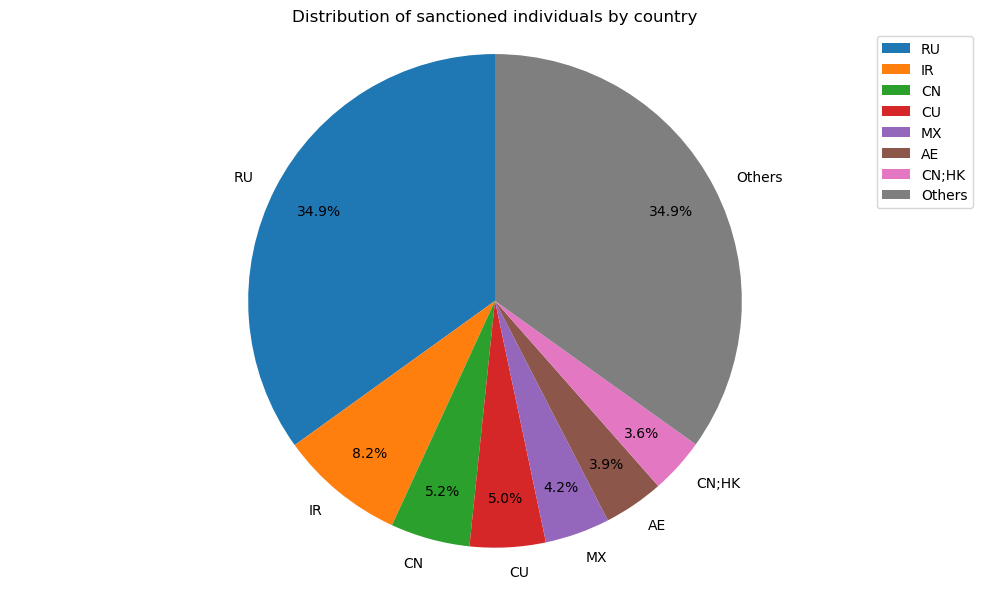

In [71]:
country_counts = df_securities['countries'].value_counts()

country_percentage = country_counts / country_counts.sum()

main_countries = country_counts[country_percentage >= 0.02]
other_countries = country_counts[country_percentage < 0.02].sum()

plot_data = main_countries.copy()
if other_countries > 0:
    plot_data['Others'] = other_countries

fig = plt.figure(figsize=(10, 6))
plot_data.plot(
    kind='pie',
    autopct='%1.1f%%', # autopct to show percentage on the pie chart
    startangle=90,
    pctdistance=0.8
)

plt.title('Distribution of sanctioned individuals by country')
plt.axis('equal')
plt.tight_layout()
plt.legend()
plt.show()

## Part II: Data Analysis and Modeling
---

| # | Question | Use Case | Technology  | Inputs |
| --- | -------- | --------------------- | -------| ------ |
| RQ1 | Which maritime vessels are potentially linked to a sanctioned entity despite not sharing a common ID - i.e. were they renamed or re-registered to conceal ownership? | Sanctions evasion via vessel renaming | **Jaccard Similarity** on character n-grams of `name` field: compare `df_maritime['name']` against `df_consolidated['name']`; pairs above threshold are candidate links | `df_maritime`, `df_consolidated` |
| RQ2 | Is there a statistically significant association between a vessel's country of sanctioned ownership and its registered flag state — in particular, do Russian- and Iranian-linked vessels disproportionately reflag to conduit jurisdictions? | Maritime sanctions evasion; dark fleet detection | Frequent Itemsets (A-Priori): baskets = vessels; items = {country:XX, flag:YY}; derive rule {country:RU} → {flag:PA} and compute confidence and lift against the baseline flag distribution; conduit_jurisdictions variable is the starting point | df_maritime, conduit_jurisdictions |
| RQ3 | Given an entity's current dataset memberships, which additional sanctions programmes is their profile most consistent with — i.e., which programmes have they not yet been listed in but should be? | Cross-list gap detection; targeted investigation | Recommendation System: build a binary entity × dataset utility matrix from datasets column; apply UV decomposition (SGD) to compute latent risk factors; score unobserved (entity, programme) pairs | df_consolidated, df_peps_def |
| RQ4 | Which non-sanctioned PEPs are most similar — by attribute profile — to the entities in df_sanctioned_people_peps, and should therefore be prioritised for enhanced due diligence? | AML/KYC prioritisation | Recommendation System (user-user collaborative filtering): Jaccard similarity on attribute sets between PEP-only entities and sanctioned PEPs; rank PEP-only entities by their average similarity to their nearest sanctioned neighbours | df_peps_def, df_sanctioned_people_peps | 
| RQ5 | Can we predict whether a PEP will also appear in the consolidated sanctions list using only the features available in their PEP profile (country count, alias count, identifier count, dataset count, top-country indicators)? | Binary risk classification; predictive compliance | LDA / QDA (already imported): label = 1 if entity ID is in df_sanctioned_people_peps, 0 if PEP-only; features derived from `countries`, `aliases`, `identifiers`, datasets columns; compare linear (LDA) and quadratic (QDA) decision boundaries | df_peps_def, df_sanctioned_people_peps |

### RQ1: Which maritime vessels are potentially linked to a sanctioned entity despite not sharing a common ID - i.e. were they renamed or re-registered to conceal ownership?

We use Jaccard Similarity to measure lexical similarity on name strings (detecting renamed vessels)

**Jaccard Similarity** on character n-grams of `name` field: compare `df_maritime['name']` against `df_consolidated['name']`; pairs above threshold are candidate links

`df_maritime`, `df_consolidated`

### RQ2: Is there a statistically significant association between a vessel's country of sanctioned ownership and its registered flag state — in particular, do Russian- and Iranian-linked vessels disproportionately reflag to conduit jurisdictions?

### RQ3: Given an entity's current dataset memberships, which additional sanctions programmes is their profile most consistent with — i.e., which programmes have they not yet been listed in but should be?

### RQ4: Which non-sanctioned PEPs are most similar — by attribute profile — to the entities in df_sanctioned_people_peps, and should therefore be prioritised for enhanced due diligence?

### RQ5: Can we predict whether a PEP will also appear in the consolidated sanctions list using only the features available in their PEP profile (country count, alias count, identifier count, dataset count, top-country indicators)?

## Part III: Machine Learning and Predictive Modeling
---

### How much better does a high-dimensional SGD classifier perform over LDA/QDA when one-hot country features are added, and what does the gap reveal about the linearity assumption?

Model benchmarking; methodology justification

Large-Scale ML (SGD classifier): same binary task as RQ5 but with full one-hot country features; compare AUC/AP against LDA/QDA baseline; the performance gap characterises whether risk is linearly separable in geographic feature space

Same inputs as of RQ5, plus one-hot encoding of `countries` 